In [ ]:
import torch
from pathlib import Path
from diffusers import UNet2DConditionModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_MODEL = "runwayml/stable-diffusion-v1-5"
CKPT_DIR  = Path("wg2diff_checkpoints/step_19000")  
ckpt_file = CKPT_DIR / "diffusion_pytorch_model.safetensors"
assert ckpt_file.exists(), f"Missing: {ckpt_file}"

unet = UNet2DConditionModel.from_pretrained(BASE_MODEL, subfolder="unet").to(device)

old = unet.conv_in
unet.conv_in = torch.nn.Conv2d(
    in_channels=5,
    out_channels=old.out_channels,
    kernel_size=old.kernel_size,
    stride=old.stride,
    padding=old.padding,
).to(device)

print("UNet conv_in now expects:", unet.conv_in.in_channels)

import safetensors.torch
state = safetensors.torch.load_file(str(ckpt_file), device="cpu")

missing, unexpected = unet.load_state_dict(state, strict=False)

print("✅ Loaded weights from:", ckpt_file)
print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))

unet.eval()


UNet conv_in now expects: 5
✅ Loaded weights from: wg2diff_checkpoints/step_19000/diffusion_pytorch_model.safetensors
Missing keys: 0
Unexpected keys: 0


UNet2DConditionModel(
  (conv_in): Conv2d(5, 320, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_proj): Timesteps()
  (time_embedding): TimestepEmbedding(
    (linear_1): Linear(in_features=320, out_features=1280, bias=True)
    (act): SiLU()
    (linear_2): Linear(in_features=1280, out_features=1280, bias=True)
  )
  (down_blocks): ModuleList(
    (0): CrossAttnDownBlock2D(
      (attentions): ModuleList(
        (0-1): 2 x Transformer2DModel(
          (norm): GroupNorm(32, 320, eps=1e-06, affine=True)
          (proj_in): Conv2d(320, 320, kernel_size=(1, 1), stride=(1, 1))
          (transformer_blocks): ModuleList(
            (0): BasicTransformerBlock(
              (norm1): LayerNorm((320,), eps=1e-05, elementwise_affine=True)
              (attn1): Attention(
                (to_q): Linear(in_features=320, out_features=320, bias=False)
                (to_k): Linear(in_features=320, out_features=320, bias=False)
                (to_v): Linear(in_features=320, out_fe

In [4]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from diffusers import AutoencoderKL, DDPMScheduler
from transformers import CLIPTextModel, CLIPTokenizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_MODEL = "runwayml/stable-diffusion-v1-5"

vae = AutoencoderKL.from_pretrained(BASE_MODEL, subfolder="vae").to(device).eval()
text_encoder = CLIPTextModel.from_pretrained(BASE_MODEL, subfolder="text_encoder").to(device).eval()
tokenizer = CLIPTokenizer.from_pretrained(BASE_MODEL, subfolder="tokenizer")
scheduler = DDPMScheduler.from_pretrained(BASE_MODEL, subfolder="scheduler")

def load_mask(mask_path, size=512):
    img = Image.open(mask_path).convert("L").resize((size, size), Image.NEAREST)
    arr = np.array(img).astype(np.float32) / 255.0
    full = torch.from_numpy(arr)[None, None].to(device)      # [1,1,512,512]
    lat  = F.interpolate(full, size=(64, 64), mode="nearest") # [1,1,64,64]
    return full, lat

@torch.no_grad()
def text_embed(prompt):
    t = tokenizer(
        prompt,
        padding="max_length",
        truncation=True,
        max_length=tokenizer.model_max_length,
        return_tensors="pt"
    )
    return text_encoder(t.input_ids.to(device)).last_hidden_state

@torch.no_grad()
def decode(latents):
    latents = latents / 0.18215
    img = vae.decode(latents).sample
    img = (img / 2 + 0.5).clamp(0, 1)
    img = (img[0].permute(1,2,0).cpu().numpy() * 255).astype(np.uint8)
    return Image.fromarray(img)

@torch.no_grad()
def generate(mask_path, prompt="a realistic clinical photograph of a chronic wound",
             steps=50, guidance=4.5, seed=0):

    torch.manual_seed(seed)

    full_mask, mask_lat = load_mask(mask_path)
    cond = text_embed(prompt)
    uncond = text_embed("")
    enc = torch.cat([uncond, cond], dim=0)

    scheduler.set_timesteps(steps, device=device)
    latents = torch.randn((1,4,64,64), device=device)

    for t in scheduler.timesteps:
        latent_in = torch.cat([latents]*2, dim=0)  # CFG batch=2
        model_in  = torch.cat([latent_in, mask_lat.repeat(2,1,1,1)], dim=1)  # [2,5,64,64]
        noise = unet(model_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise.chunk(2)
        noise = n_u + guidance*(n_c - n_u)
        latents = scheduler.step(noise, t, latents).prev_sample

    return decode(latents), full_mask


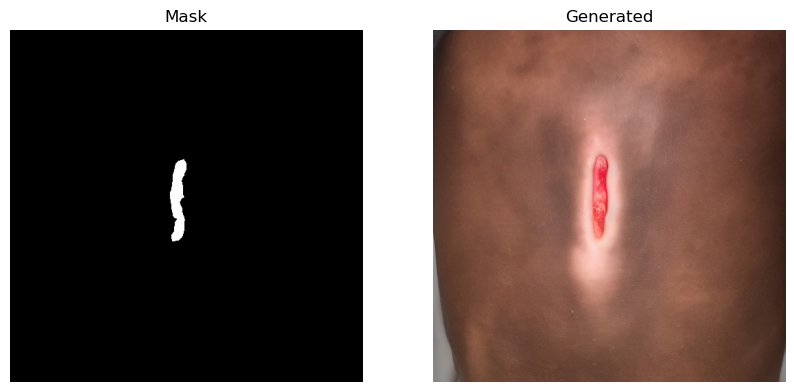

In [ ]:
MASK_PATH = "final_dataset/final_dataset/AZH_masks/AZH_00000.png"  # <-- change if needed

img, mask = generate(
    MASK_PATH,
    seed=42,
    steps=50,          # 30 for faster, 75 for higher quality
    guidance=4.5
)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.title("Mask"); plt.axis("off")
plt.imshow(mask[0,0].detach().cpu().numpy(), cmap="gray")

plt.subplot(1,2,2); plt.title("Generated"); plt.axis("off")
plt.imshow(img)
plt.show()


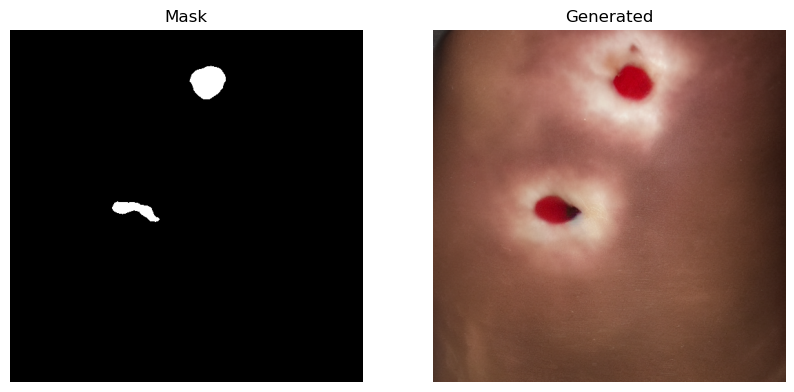

In [6]:
MASK_PATH = "final_dataset/final_dataset/AZH_masks/AZH_00001.png"  # <-- change if needed

img, mask = generate(
    MASK_PATH,
    seed=42,
    steps=50,          # try 30 for faster, 75 for higher quality
    guidance=4.5
)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.title("Mask"); plt.axis("off")
plt.imshow(mask[0,0].detach().cpu().numpy(), cmap="gray")

plt.subplot(1,2,2); plt.title("Generated"); plt.axis("off")
plt.imshow(img)
plt.show()


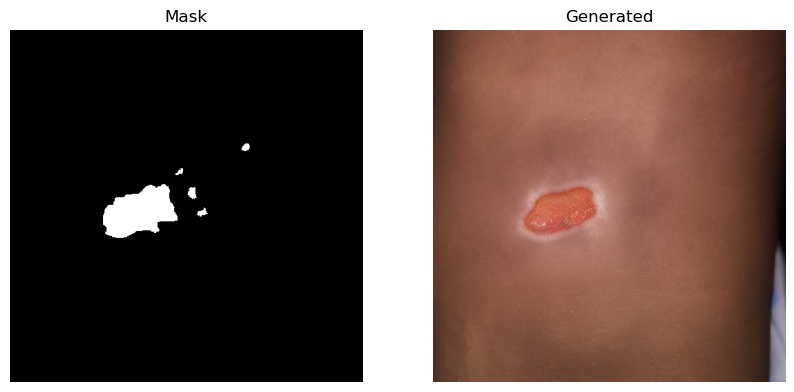

In [8]:
MASK_PATH = "final_dataset/final_dataset/Kaggle_Masks/fusc_0136.png"  # <-- change if needed

img, mask = generate(
    MASK_PATH,
    seed=42,
    steps=50,          # try 30 for faster, 75 for higher quality
    guidance=4.5
)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.title("Mask"); plt.axis("off")
plt.imshow(mask[0,0].detach().cpu().numpy(), cmap="gray")

plt.subplot(1,2,2); plt.title("Generated"); plt.axis("off")
plt.imshow(img)
plt.show()


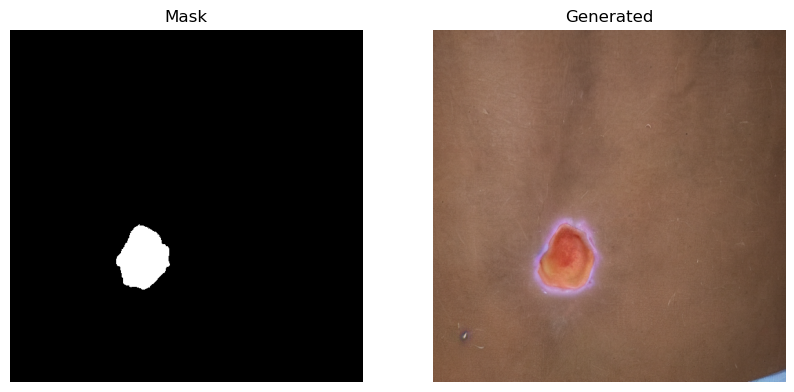

In [9]:
MASK_PATH = "final_dataset/final_dataset/Kaggle_Masks/fusc_0003.png"  # <-- change if needed

img, mask = generate(
    MASK_PATH,
    seed=42,
    steps=150,          # try 30 for faster, 75 for higher quality
    guidance=4.5
)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.title("Mask"); plt.axis("off")
plt.imshow(mask[0,0].detach().cpu().numpy(), cmap="gray")

plt.subplot(1,2,2); plt.title("Generated"); plt.axis("off")
plt.imshow(img)
plt.show()


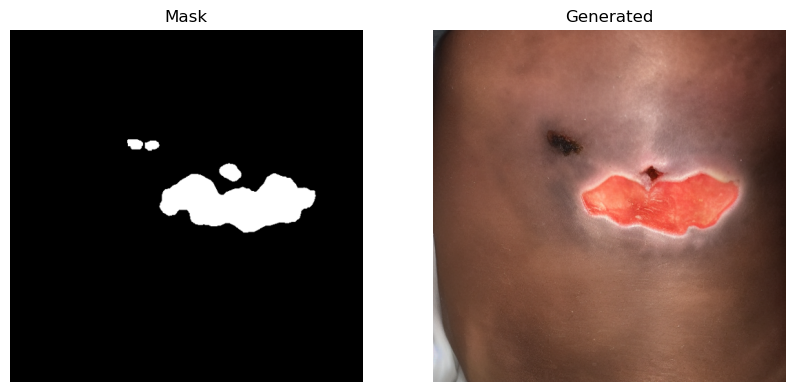

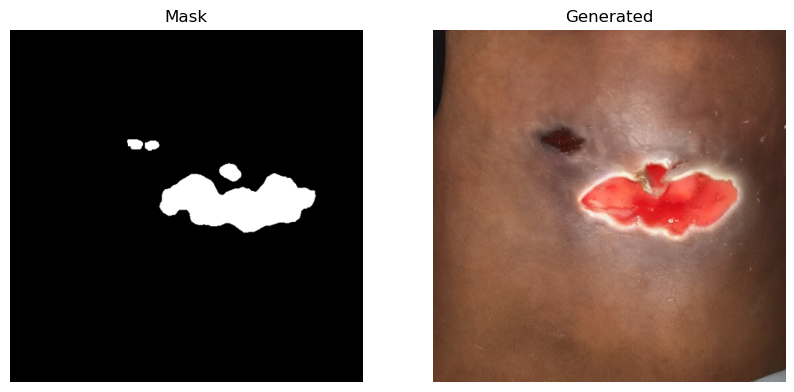

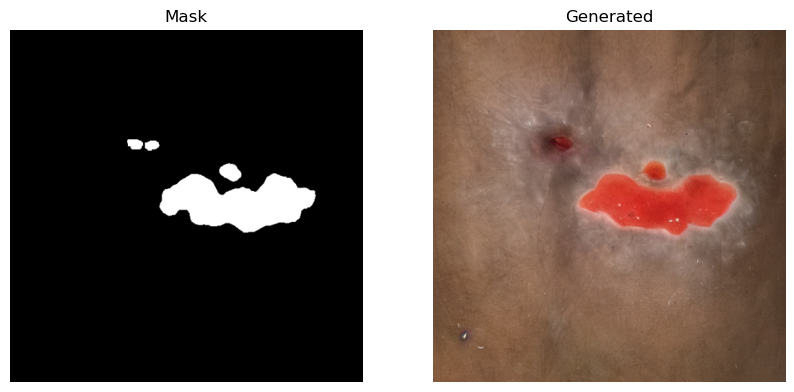

In [11]:
MASK_PATH = "final_dataset/final_dataset/Kaggle_Masks/medetec_0143.png"  # <-- change if needed

img, mask = generate(
    MASK_PATH,
    seed=42,
    steps=50,          # try 30 for faster, 75 for higher quality
    guidance=4.5
)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.title("Mask"); plt.axis("off")
plt.imshow(mask[0,0].detach().cpu().numpy(), cmap="gray")

plt.subplot(1,2,2); plt.title("Generated"); plt.axis("off")
plt.imshow(img)
plt.show()
img, mask = generate(
    MASK_PATH,
    seed=42,
    steps=100,          # try 30 for faster, 75 for higher quality
    guidance=4.5
)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.title("Mask"); plt.axis("off")
plt.imshow(mask[0,0].detach().cpu().numpy(), cmap="gray")

plt.subplot(1,2,2); plt.title("Generated"); plt.axis("off")
plt.imshow(img)
plt.show()
img, mask = generate(
    MASK_PATH,
    seed=42,
    steps=150,          # try 30 for faster, 75 for higher quality
    guidance=4.5
)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.title("Mask"); plt.axis("off")
plt.imshow(mask[0,0].detach().cpu().numpy(), cmap="gray")

plt.subplot(1,2,2); plt.title("Generated"); plt.axis("off")
plt.imshow(img)
plt.show()